In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab Notebooks/capstone

# Pastikan dataset skincare_clean.csv ada di dalam daftar
print(os.listdir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab Notebooks/capstone
['Skincare Treatment Dataset.csv', 'skincare_clean_fix.csv', 'Cleaning_dataset.ipynb', 'Untitled0.ipynb']


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tema grafik yang rapi untuk semua praktikum
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

In [4]:
df = pd.read_csv('skincare_clean_fix.csv')

print('Ukuran data (baris, kolom):', df.shape)
df.head()

Ukuran data (baris, kolom): (1120, 9)


,age_group,skin_type,skin_subtype,sensitivity,concern,internal_type,ingredients,concentrations,effects
0,14-18,0,normal to dry,1,acne,comedonal,Zinc PCA + Benzoyl Peroxide + Salicylic Acid,0.5% + 2% + 5%,"Controls sebum production, Kills acne-causing ..."
1,14-18,0,normal to dry,1,acne,inflammatory,Zinc PCA + Benzoyl Peroxide + Niacinamide,0.5% + 5% + 1%,"Controls sebum production, Kills acne-causing ..."
2,14-18,0,normal to dry,1,acne,nodular,Zinc PCA + Azelaic Acid + Salicylic Acid,10% + 1% + 5%,"Controls sebum production, Reduces acne and im..."
3,14-18,0,normal to dry,1,acne,cystic,Benzoyl Peroxide + Niacinamide + Azelaic Acid,10% + 1% + 8%,"Kills acne-causing bacteria, Reduces inflammat..."
4,14-18,0,normal to dry,1,dark circles,pigmented,Hyaluronic Acid + Caffeine + Vitamin C,3% + 2% + 0.5%,"Hydrates and plumps the skin, Reduces puffines..."


In [10]:
# Kamus: kode angka -> nama asli (kebalikan dari encoding di Pertemuan 3)
peta_skin_type = {0: 'normal', 1: 'dry', 2: 'oily', 3: 'combination'}
peta_sensitivity = {0: 'no', 1: 'yes'}

# Salinan khusus EDA; df asli (angka) tetap utuh untuk modeling
eda = df.copy()
eda['skin_type_label'] = eda['skin_type'].map(peta_skin_type)
eda['sensitivity_label'] = eda['sensitivity'].map(peta_sensitivity)

eda.head()

,age_group,skin_type,skin_subtype,sensitivity,concern,internal_type,ingredients,concentrations,effects,skin_type_label,sensitivity_label
0,14-18,0,normal to dry,1,acne,comedonal,Zinc PCA + Benzoyl Peroxide + Salicylic Acid,0.5% + 2% + 5%,"Controls sebum production, Kills acne-causing ...",normal,yes
1,14-18,0,normal to dry,1,acne,inflammatory,Zinc PCA + Benzoyl Peroxide + Niacinamide,0.5% + 5% + 1%,"Controls sebum production, Kills acne-causing ...",normal,yes
2,14-18,0,normal to dry,1,acne,nodular,Zinc PCA + Azelaic Acid + Salicylic Acid,10% + 1% + 5%,"Controls sebum production, Reduces acne and im...",normal,yes
3,14-18,0,normal to dry,1,acne,cystic,Benzoyl Peroxide + Niacinamide + Azelaic Acid,10% + 1% + 8%,"Kills acne-causing bacteria, Reduces inflammat...",normal,yes
4,14-18,0,normal to dry,1,dark circles,pigmented,Hyaluronic Acid + Caffeine + Vitamin C,3% + 2% + 0.5%,"Hydrates and plumps the skin, Reduces puffines...",normal,yes


In [11]:
# 1. Ukuran data (jumlah baris, jumlah kolom)
print('Ukuran data:', df.shape)

# 2. Tipe data setiap kolom
df.info()

# 3. Nilai kosong dan baris kembar
print('\nNilai kosong per kolom:')
print(df.isnull().sum())
print('\nJumlah baris kembar:', df.duplicated().sum())

# 4. Distribusi nilai unik pada kolom kategori utama
print('\nDistribusi Kelompok Usia (age_group):')
print(df['age_group'].value_counts())
print('\nDistribusi Tipe Kulit (skin_type):')
print(df['skin_type'].value_counts())

Ukuran data: (1120, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1120 entries, 0 to 1119
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age_group       1120 non-null   object
 1   skin_type       1120 non-null   int64 
 2   skin_subtype    1120 non-null   object
 3   sensitivity     1120 non-null   int64 
 4   concern         1120 non-null   object
 5   internal_type   1120 non-null   object
 6   ingredients     1120 non-null   object
 7   concentrations  1120 non-null   object
 8   effects         1120 non-null   object
dtypes: int64(2), object(7)
memory usage: 78.9+ KB

Nilai kosong per kolom:
age_group         0
skin_type         0
skin_subtype      0
sensitivity       0
concern           0
internal_type     0
ingredients       0
concentrations    0
effects           0
dtype: int64

Jumlah baris kembar: 0

Distribusi Kelompok Usia (age_group):
age_group
14-18    224
19-24    224
25-36    224
37-45 

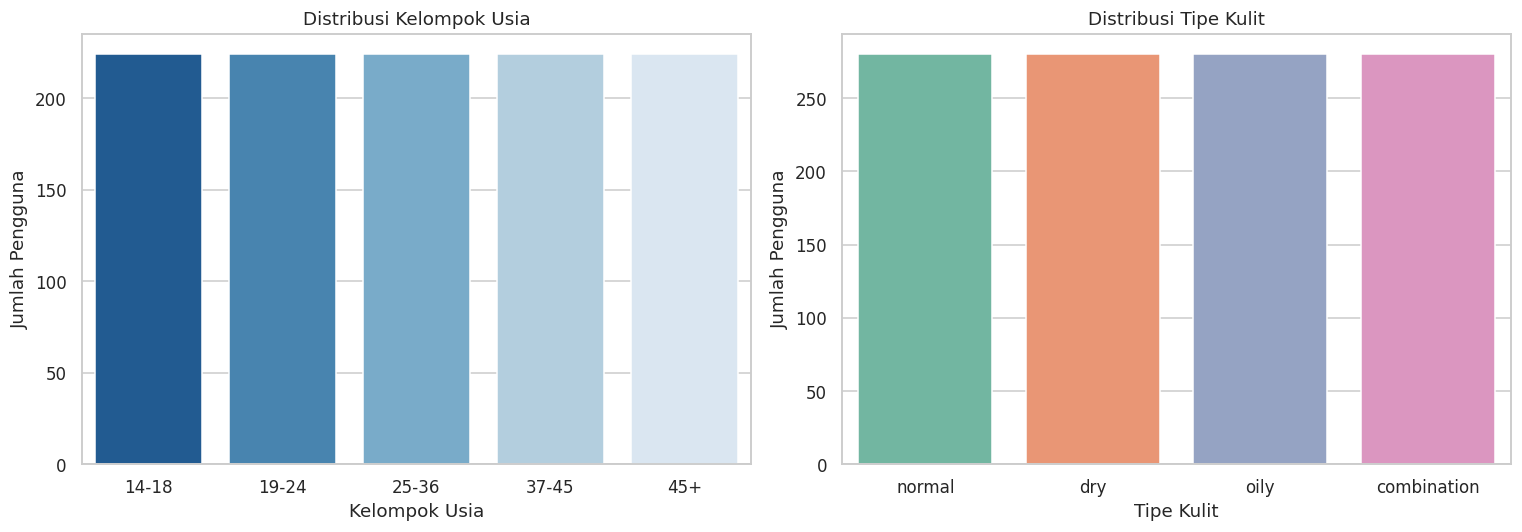

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Kiri: Distribusi Kelompok Usia (age_group)
sns.countplot(data=eda, x='age_group', hue='age_group', palette='Blues_r', ax=axes[0], legend=False)
axes[0].set_title('Distribusi Kelompok Usia')
axes[0].set_xlabel('Kelompok Usia')
axes[0].set_ylabel('Jumlah Pengguna')

# Kanan: Distribusi Tipe Kulit (skin_type_label)
sns.countplot(data=eda, x='skin_type_label', hue='skin_type_label', palette='Set2', ax=axes[1], legend=False)
axes[1].set_title('Distribusi Tipe Kulit')
axes[1].set_xlabel('Tipe Kulit')
axes[1].set_ylabel('Jumlah Pengguna')

plt.tight_layout()
plt.show()

* Grafik Kiri (Kelompok Usia): Menunjukkan distribusi seimbang untuk semua kelompok usia dari 14-18 hingga 45+ dengan masing-masing 224 data.

* Grafik Kanan (Tipe Kulit): Menunjukkan distribusi yang sama rata di antara tipe kulit normal, dry, oily, dan combination dengan masing-masing 280 data.

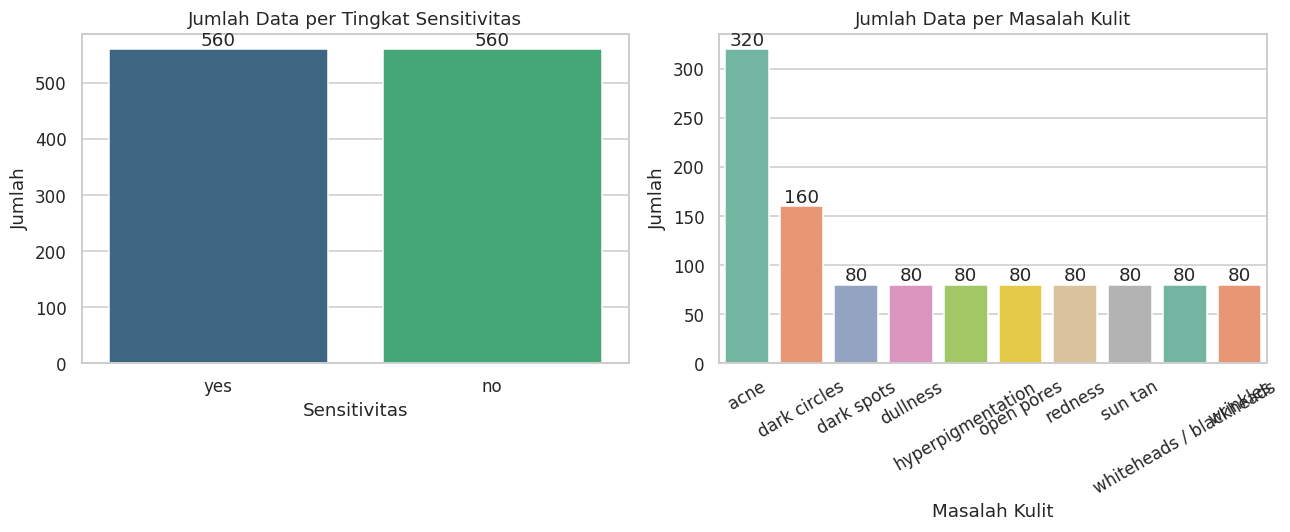

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Kiri: jumlah data berdasarkan tingkat sensitivitas
sns.countplot(data=eda, x='sensitivity_label', hue='sensitivity_label',
              palette='viridis', legend=False, dodge=False, ax=axes[0])
axes[0].set_title('Jumlah Data per Tingkat Sensitivitas')
axes[0].set_xlabel('Sensitivitas')
axes[0].set_ylabel('Jumlah')

# Kanan: jumlah data berdasarkan masalah kulit
sns.countplot(data=eda, x='concern', hue='concern',
              palette='Set2', legend=False, dodge=False, ax=axes[1])
axes[1].set_title('Jumlah Data per Masalah Kulit')
axes[1].set_xlabel('Masalah Kulit')
axes[1].set_ylabel('Jumlah')
axes[1].tick_params(axis='x', rotation=30)

# Tampilkan angka di atas setiap batang
for ax in axes:
    for wadah in ax.containers:
        ax.bar_label(wadah)

plt.tight_layout()
plt.show()

* Grafik Kiri (Tingkat Sensitivitas): Menunjukkan jumlah data pengguna dengan kulit sensitif (yes sebanyak 560 data) dan tidak sensitif (no sebanyak 560 data).

* Grafik Kanan (Masalah Kulit): Menampilkan sebaran data berdasarkan keluhan atau masalah kulit pengguna (acne, dark circles, dll.) secara proporsional lengkap dengan angka di atas setiap diagram batang.

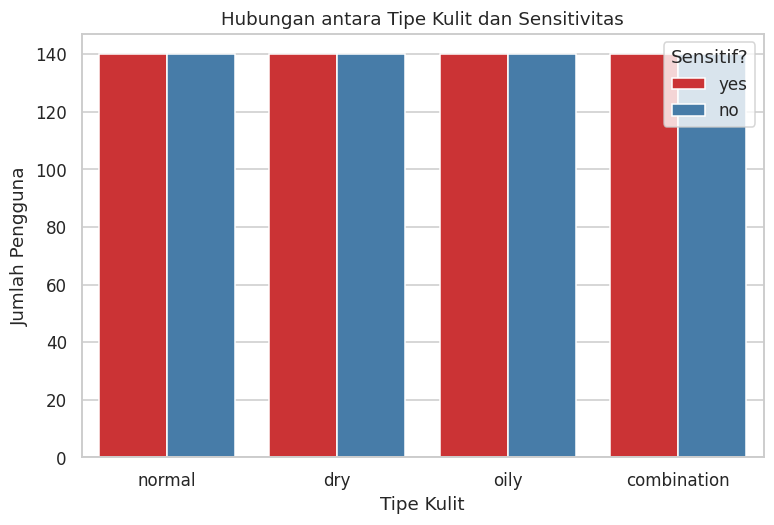

In [14]:
plt.figure(figsize=(8, 5))

# Memvisualisasikan hubungan antara Tipe Kulit dan Sensitivitas Kulit
sns.countplot(data=eda, x='skin_type_label', hue='sensitivity_label', palette='Set1')

plt.title('Hubungan antara Tipe Kulit dan Sensitivitas')
plt.xlabel('Tipe Kulit')
plt.ylabel('Jumlah Pengguna')
plt.legend(title='Sensitif?')
plt.show()

Visualisasi hubungan antara Tipe Kulit dan Sensitivitas pada sel _1TjgQz9ZCgh telah berhasil dijalankan dan ditampilkan dengan sukses.

Grafik tersebut menunjukkan distribusi tingkat sensitivitas kulit ('yes' atau 'no') untuk setiap kategori tipe kulit ('normal', 'dry', 'oily', dan 'combination') secara terperinci.

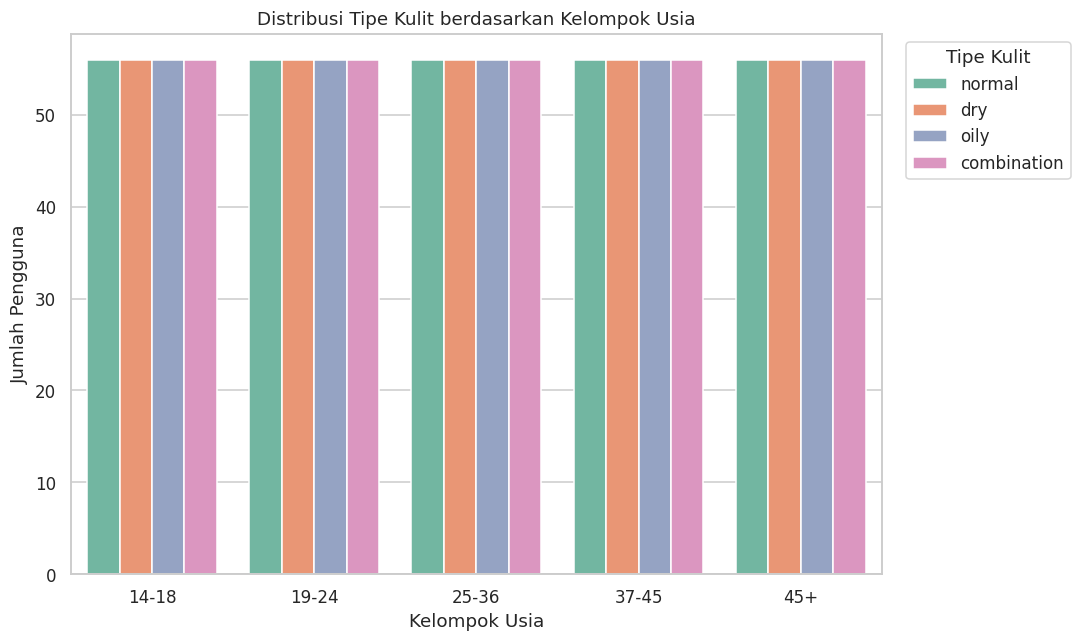

In [16]:
plt.figure(figsize=(10, 6))

# Mengurutkan kelompok usia agar tampil berurutan di grafik
urutan_usia = ['14-18', '19-24', '25-36', '37-45', '45+']

# Memvisualisasikan Tipe Kulit berdasarkan Kelompok Usia
sns.countplot(data=eda, x='age_group', order=urutan_usia, hue='skin_type_label', palette='Set2')

plt.title('Distribusi Tipe Kulit berdasarkan Kelompok Usia')
plt.xlabel('Kelompok Usia')
plt.ylabel('Jumlah Pengguna')
plt.legend(title='Tipe Kulit', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

Visualisasi tersebut menunjukkan Distribusi Tipe Kulit berdasarkan Kelompok Usia (dari rentang 14-18 hingga 45+). Setiap kelompok usia menunjukkan proporsi tipe kulit yang terdistribusi secara merata di dalam dataset skincare

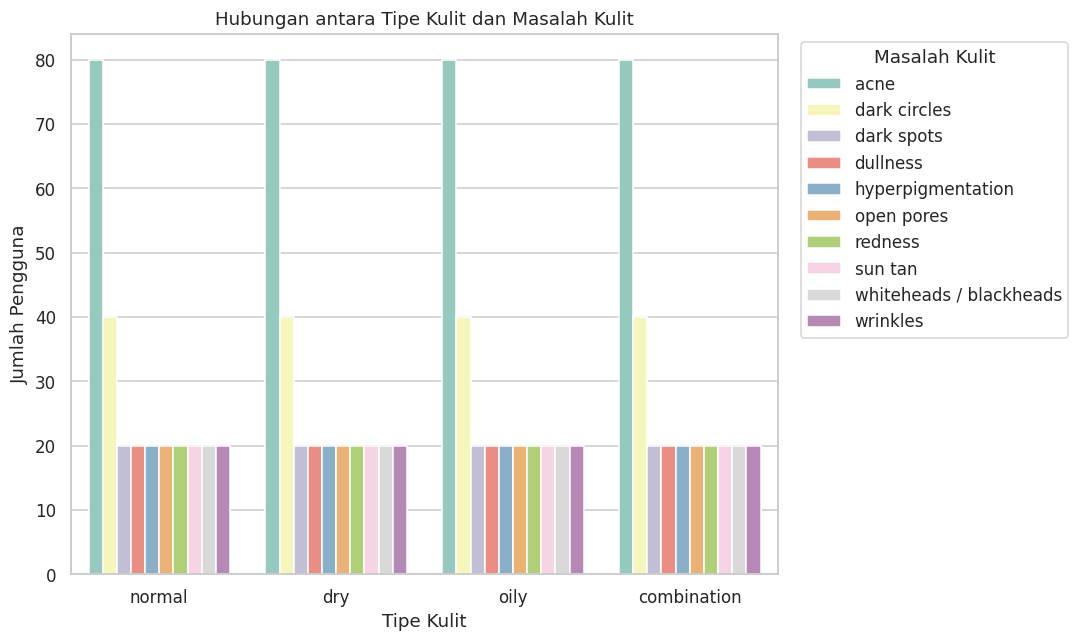

In [17]:
plt.figure(figsize=(10, 6))

# Memvisualisasikan hubungan antara Tipe Kulit dan Masalah Kulit (Concern)
sns.countplot(data=eda, x='skin_type_label', hue='concern', palette='Set3')

plt.title('Hubungan antara Tipe Kulit dan Masalah Kulit')
plt.xlabel('Tipe Kulit')
plt.ylabel('Jumlah Pengguna')
plt.legend(title='Masalah Kulit', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

memvisualisasikan sebaran masalah kulit (concern) berdasarkan tipe kulit (skin_type_label) untuk melihat kecenderungan masalah kulit pada setiap tipe kulit

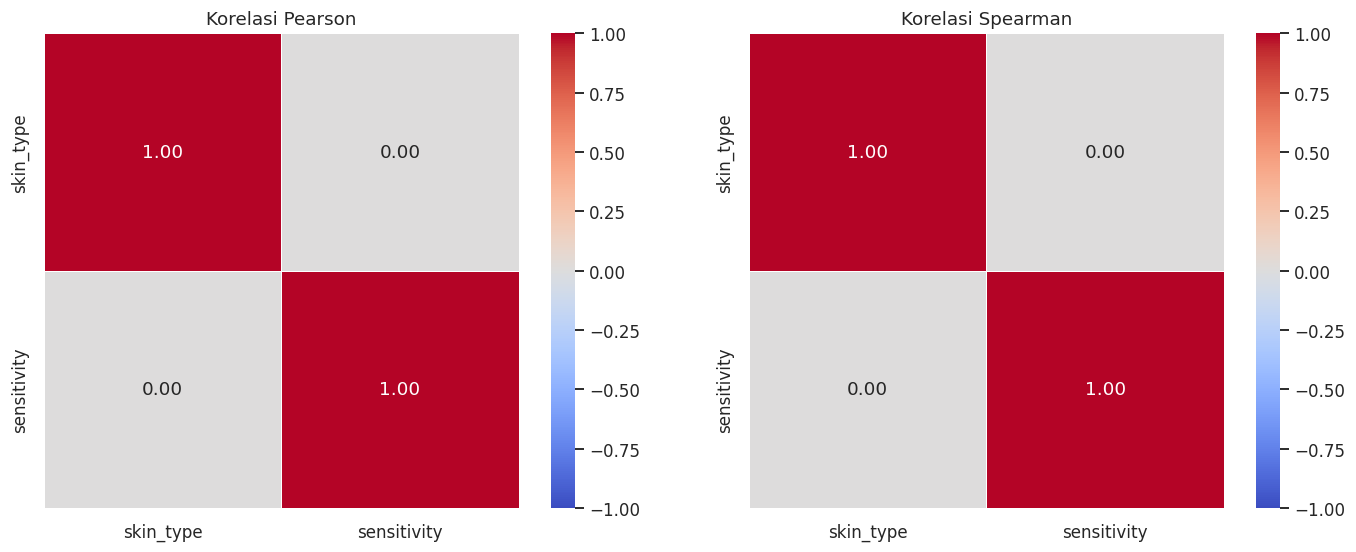

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Memilih kolom numerik dari dataset skincare untuk korelasi
kolom_numerik = df[['skin_type', 'sensitivity']]

for ax, metode in zip(axes, ['pearson', 'spearman']):
    korelasi = kolom_numerik.corr(method=metode)
    sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm',
                vmin=-1, vmax=1, center=0, square=True,
                linewidths=0.5, ax=ax)
    ax.set_title(f'Korelasi {metode.capitalize()}')

plt.tight_layout()
plt.show()

Visualisasi heatmap tersebut memperlihatkan kekuatan hubungan korelasi menggunakan metode Pearson dan Spearman untuk variabel numerik yang ada (skin_type dan sensitivity) pada dataset skincare

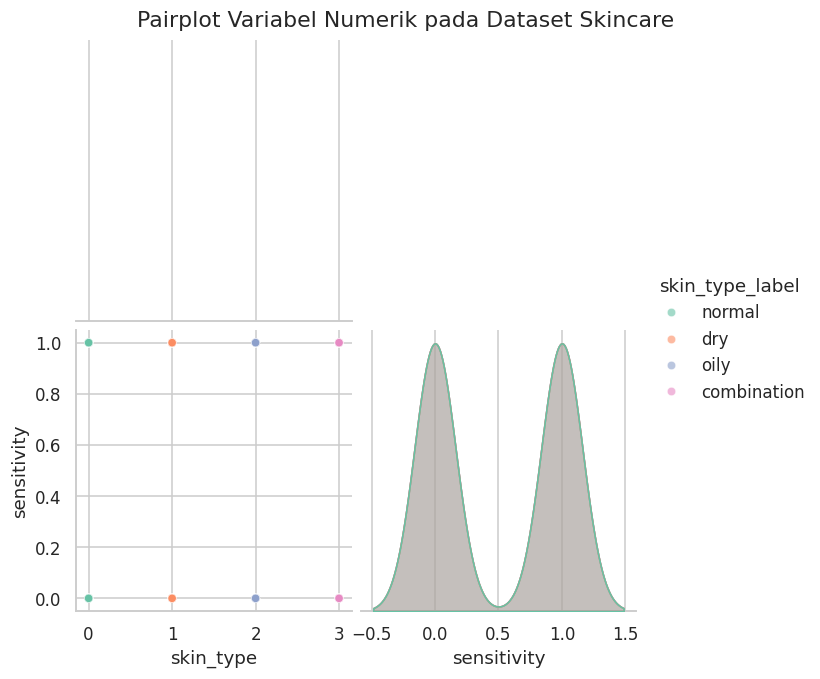

In [19]:
# Membuat Pairplot untuk kolom numerik di dataset skincare
g = sns.pairplot(
    eda[['skin_type', 'sensitivity', 'skin_type_label']],
    hue='skin_type_label',
    palette='Set2',
    corner=True,
    plot_kws={'alpha': 0.6, 's': 30},
    height=3
)
g.figure.suptitle('Pairplot Variabel Numerik pada Dataset Skincare', y=1.02)
plt.show()

Visualisasi tersebut menunjukkan hubungan berpasangan (scatter plot dan histogram) antara variabel numerik skin_type (tipe kulit) dan sensitivity (tingkat sensitivitas) dengan pewarnaan berdasarkan skin_type_label.

In [20]:
(eda.groupby('skin_type_label', observed=True)[['sensitivity']]
 .agg(['count', 'mean', 'sum'])
 .round(2))

sensitivity          
                      count mean  sum
skin_type_label                      
combination             280  0.5  140
dry                     280  0.5  140
normal                  280  0.5  140
oily                    280  0.5  140

* Setiap kategori tipe kulit (combination, dry, normal, oily) memiliki jumlah data (count) yang sama, yaitu masing-masing 280.

* Rata-rata (mean) sensitivitas di setiap kelompok adalah 0.5, dengan jumlah total (sum) pengguna dengan tipe kulit sensitif adalah 140 di setiap kelompok. Ini menunjukkan pembagian data sensitivitas yang sangat seimbang (50% sensitif, 50% tidak sensitif) di setiap tipe kulit.